In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

data = pd.read_csv('../Data/creditcard_clean.csv')

x = data.drop(columns=['Class', 'Hour'], errors='ignore')
y = data['Class']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# balance the training data only
train = x_train.copy()
train['Class'] = y_train
class_1 = train[train['Class'] == 1]
class_0 = train[train['Class'] == 0].sample(len(class_1), random_state=42)
train_bal = pd.concat([class_0, class_1])
x_bal = train_bal.drop('Class', axis=1)
y_bal = train_bal['Class']

print(y_bal.value_counts())

Class
0    378
1    378
Name: count, dtype: int64


## Train the models

In [3]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_bal, y_bal)
pred_knn = knn.predict(x_test)

In [4]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_bal, y_bal)
pred_lr = lr.predict(x_test)

In [5]:
nb = GaussianNB()
nb.fit(x_bal, y_bal)
pred_nb = nb.predict(x_test)

In [6]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_bal, y_bal)
pred_dt = dt.predict(x_test)

In [7]:
svm = SVC()
svm.fit(x_bal, y_bal)
pred_svm = svm.predict(x_test)

## Comparison table

In [8]:
print("KNN                :", accuracy_score(y_test, pred_knn))
print("Logistic Regression:", accuracy_score(y_test, pred_lr))
print("Naive Bayes        :", accuracy_score(y_test, pred_nb))
print("Decision Tree      :", accuracy_score(y_test, pred_dt))
print("SVM                :", accuracy_score(y_test, pred_svm))

KNN                : 0.9762802664504987
Logistic Regression: 0.9724209635921475
Naive Bayes        : 0.9689845980333416
Decision Tree      : 0.8965037183237585
SVM                : 0.986430761639587


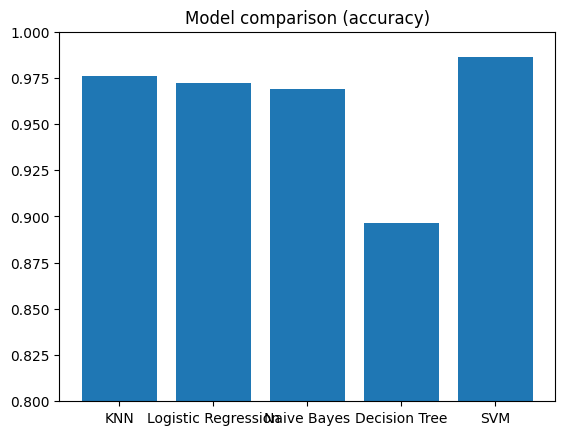

In [16]:
names = ['KNN', 'Logistic Regression', 'Naive Bayes', 'Decision Tree', 'SVM']
acc = [accuracy_score(y_test, pred_knn),
       accuracy_score(y_test, pred_lr),
       accuracy_score(y_test, pred_nb),
       accuracy_score(y_test, pred_dt),
       accuracy_score(y_test, pred_svm)]

plt.bar(names, acc)
plt.title('Model comparison (accuracy)')
plt.ylim(0.8, 1)
plt.show()

## Best model

In [11]:
acc = [accuracy_score(y_test, pred_knn),
       accuracy_score(y_test, pred_lr),
       accuracy_score(y_test, pred_nb),
       accuracy_score(y_test, pred_dt),
       accuracy_score(y_test, pred_svm)]
names = ['KNN', 'Logistic Regression', 'Naive Bayes', 'Decision Tree', 'SVM']

print('Best model:', names[acc.index(max(acc))])

Best model: SVM


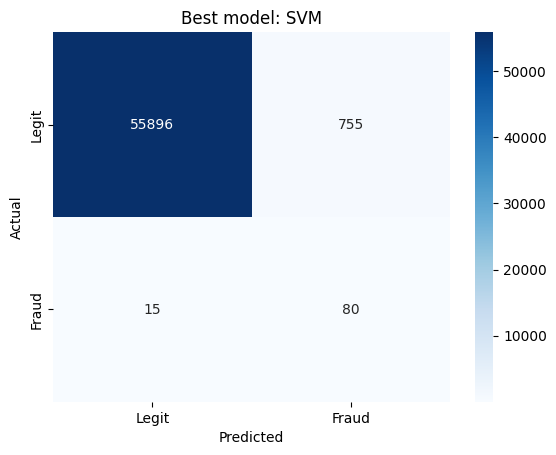

In [12]:
best = 'SVM'
cm = confusion_matrix(y_test, pred_svm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
plt.title('Best model: ' + best)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Conclusion
- Accuracy is high for most models because legit transactions are the vast majority, so it is not used to choose the best model.
- The best model is the one printed above (highest F1). Mention its recall: how many frauds it caught out of the total.
- Precision is low for all models because only the training data was balanced. Many legit transactions get flagged as fraud (false alarms).